# Point-source detection in simulated images

We compare source-count probabilities from prior-based and network-based source selection with an independent numerical integration. Images have two known candidate positions, a Gaussian point-spread function, and independent Gaussian pixel noise. The short run below checks execution. The manuscript results use two chains of 20,000 iterations per image.

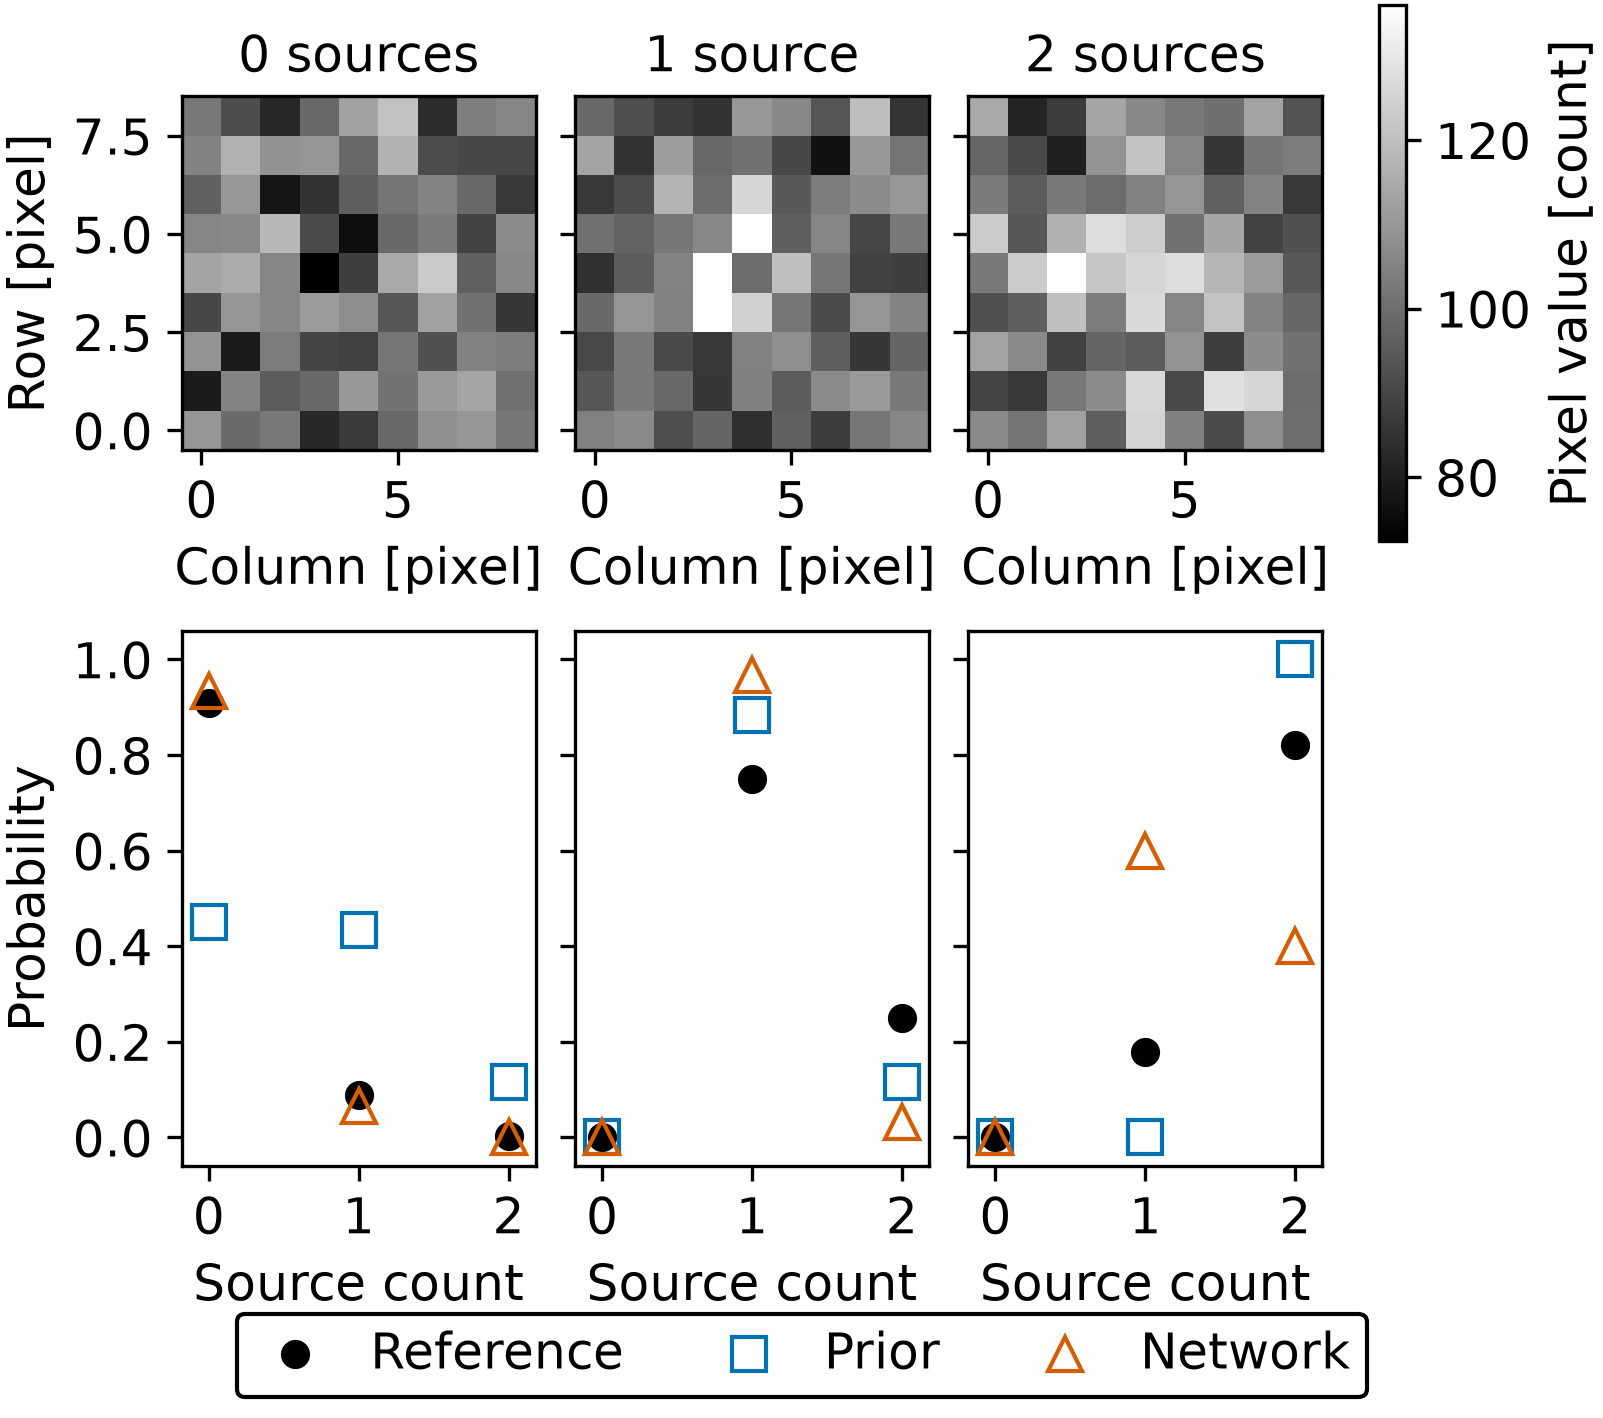

[{'reference_count_probability': [0.908075390657309,
   0.0891617756461345,
   0.002762833696554525],
  'runs': [{'method': 'prior',
    'chain': 0,
    'seed': 273,
    'seconds': 0.0022623750010097865,
    'count_probability': [0.0, 0.7666666666666667, 0.23333333333333334],
    'acceptance_counts': {'within': 23, 'birth': 4, 'death': 3}},
   {'method': 'prior',
    'chain': 1,
    'seed': 274,
    'seconds': 0.002050167000561487,
    'count_probability': [0.9, 0.1, 0.0],
    'acceptance_counts': {'within': 24, 'birth': 2, 'death': 2}},
   {'method': 'prior',
    'combined_count_probability': [0.45,
     0.43333333333333335,
     0.11666666666666667],
    'total_variation_from_reference': 0.45807539065730996},
   {'method': 'neural',
    'chain': 0,
    'seed': 273,
    'seconds': 0.012658042000111891,
    'count_probability': [1.0, 0.0, 0.0],
    'acceptance_counts': {'within': 24, 'birth': 0, 'death': 0}},
   {'method': 'neural',
    'chain': 1,
    'seed': 274,
    'seconds': 0.012

In [1]:
import json
from contextlib import redirect_stdout
from io import StringIO
from uuid import uuid4

from pcat.demo import display_example_visuals, load_example_namespace, run_example_script
from tdpy.verbosity import print

run_id = f"point_source_notebook_{uuid4().hex[:12]}"
with redirect_stdout(StringIO()):
    run_example_script(
        "neural_proposal_efficiency/point_source_detection.py",
        "--smoke", "--run-id", run_id,
    )
    example = load_example_namespace("neural_proposal_efficiency/point_source_detection.py")
root = example["Path"](example["__file__"]).parent
result_path = root / "data" / f"{run_id}_point_sources.json"
print(f"Reading from {result_path.name}...")
with result_path.open(encoding="utf-8") as stream:
    cases = json.load(stream)["cases"]
with redirect_stdout(StringIO()):
    display_example_visuals("neural_proposal_efficiency", f"visuals/{run_id}_point_sources.png")
cases